In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/allisonhorst/palmerpenguins/main/inst/extdata/penguins.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Loaded Successfully!
Dataset Shape: (344, 8)
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  year  
0       3750.0    male  2007  
1       3800.0  female  2007  
2       3250.0  female  2007  
3          NaN     NaN  2007  
4       3450.0  female  2007  


In [2]:
print("Dataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSpecies Count:")
print(df["species"].value_counts())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB
None

Missing Values:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Species Count:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Statistical Summar

In [3]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

df = df.dropna(subset=features + ["species"])

print("Missing Values Removed Successfully!")
print("New Dataset Shape:", df.shape)
print("\nMissing Values After Cleaning:")
print(df[features + ["species"]].isnull().sum())

Missing Values Removed Successfully!
New Dataset Shape: (342, 8)

Missing Values After Cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
species              0
dtype: int64


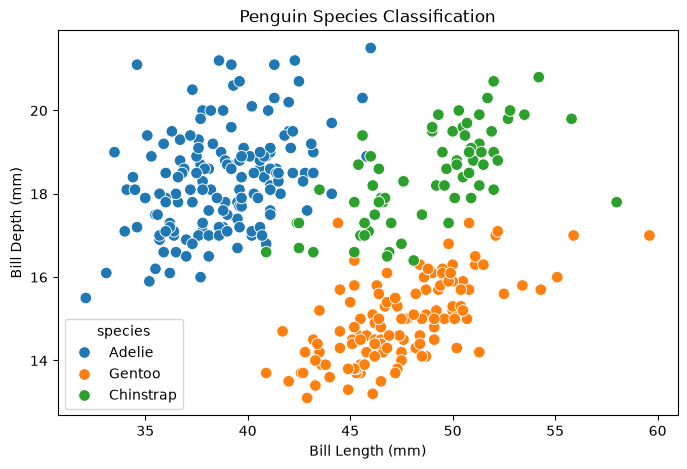

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="bill_length_mm", y="bill_depth_mm", hue="species", s=70)
plt.title("Penguin Species Classification")
plt.xlabel("Bill Length (mm)")
plt.ylabel("Bill Depth (mm)")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Data Splitting Successfully Completed!")
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Data Splitting Successfully Completed!
Training Data: (273, 4)
Testing Data: (69, 4)


In [6]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69


Confusion Matrix:
[[30  0  0]
 [ 0 14  0]
 [ 0  0 25]]


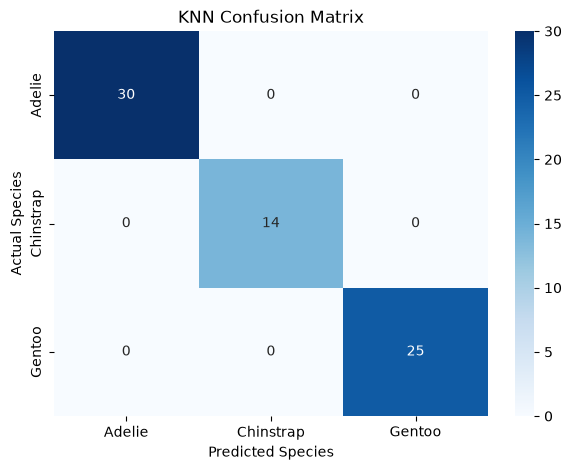

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=knn.classes_,
            yticklabels=knn.classes_)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [10]:
sample = pd.DataFrame(
    [[39.1, 18.7, 181, 3750]],
    columns=features
)

sample_scaled = scaler.transform(sample)

prediction = knn.predict(sample_scaled)

print("Predicted Penguin Species:", prediction[0])

Predicted Penguin Species: Adelie


In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(model, X, y, cv=cv)

print("Cross Validation Scores:", scores)
print("Average Accuracy:", round(scores.mean() * 100, 2), "%")

Cross Validation Scores: [0.98550725 1.         0.98529412 0.98529412 0.98529412]
Average Accuracy: 98.83 %
